## Financial Impact Analysis: SCOR (Measure/Return)

### Strategic Framing

While demand forecasting and service execution provide visibility into how the supply chain operates, Financial Impact Analysis evaluates whether it operates profitably. This notebook translates operational execution into economic outcomes, moving from supply chain visibility to supply chain profitability measurement.

Within the SCOR Model, this analysis is anchored in two critical phases:

- **Measure:** Quantifying end-to-end financial performance and profit realization across markets, categories, and customers.
- **Return:** Capturing the cost of failure - the financial leakage tied to service errors, pricing instability, and reverse logistics.

### Business Questions Driving the Analysis

The diagnostic is structured around three executive-level pillars:

**1. Profit Concentration: The Growth vs. Erosion Map**

Which segments generate profit, and which erode it? The DataCo dataset is segmented to identify:

- High-Margin Growth Engines: Segments to prioritise for investment.
- Low-Margin Volume Traps: Segments requiring pricing or fulfillment restructuring.
- Servicing Cost Disparity: Customers with disproportionate logistics requirements.

**2. Profit Leakage Attribution: The Hidden Costs**

Even with strong top-line revenue, execution inefficiencies drain margins. Leakage is decomposed into three SCOR-aligned channels:

- Discounts (Plan → Measure): Pricing leakage and the margin erosion caused by promotional dependency. Identified as the dominant leakage driver.
- Late Delivery (Deliver → Measure): Value-at-Risk tied to service failures - credits, churn risk, and expedited shipping.
- Returns and Cancellations (Return → Measure): Reverse logistics profit erosion. A smaller but monitored channel.

**3. Prescriptive Action: Strategy Design**

What are the implied levers for the business?

- Pricing Strategy: Enterprise-level discount governance and margin floors.
- Shipping Optimization: Carrier mix and premium-mode rebalancing for high-value orders in tipping-point regions.
- Return Policy: Monitor; no investment in policy changes at current leakage levels.

### Analytical Outputs

The notebook produces five core outputs:

**1. Profit Concentration Analysis:** Multi-grain segmentation (market, category, customer segment, individual customer) identifying where profit is created, diluted, or destroyed.

**2. Profit Waterfall:** A visual decomposition from Gross Revenue through Discounts, Late Delivery Penalties, and Return Impact to Net Realized Profit.

**3. Segment Profitability Metrics:** Profit per Order, Adjusted Margin, Leakage Intensity, and Service Cost Exposure for segment benchmarking.

**4. Sensitivity Analysis:** Stress-testing the late-delivery penalty assumption at 1%, 3%, and 5% to identify tipping-point regions and margin-resilient segments.

**5. Strategic Recommendations:** Prioritised, quantified margin recovery levers with expected dollar impact.

### Integrated SCOR Interpretation

| SCOR Phase | Financial Insight Generated |
|------------|-----------------------------|
| Plan | Discount strategy impact on profitability; pricing governance. |
| Deliver | Late delivery value-at-risk; service failure cost exposure. |
| Return | Reverse logistics profit erosion monitoring. |
| Measure | End-to-end profit realization; adjusted margin as primary KPI. |

### Strategic Value

By closing the loop between operational execution and financial performance, this analysis enables decision-makers to answer three questions:

- Where should the business grow?
- What should the business fix?
- And where should the business divest?

**Note:** All financial values are reported in **USD ($)** unless otherwise specified.

## Data Ingestion

In [ ]:
import pandas as pd
import numpy as np

# Set display options for dataframe
pd.set_option("display.max_columns", 80)

# Load cleaned dataset 
orders_silver = pd.read_parquet("/kaggle/input/datasets/orders-silver/orders_silver.parquet")
orders_silver.head()

,type,days_for_shipping_real,days_for_shipment_scheduled,benefit_per_order,sales_per_customer,delivery_status,late_delivery_risk,category_id,category_name,customer_city,customer_country,customer_email,customer_fname,customer_id,customer_lname,customer_password,customer_segment,customer_state,customer_street,customer_zipcode,department_id,department_name,latitude,longitude,market,order_city,order_country,order_customer_id,order_date,order_id,order_item_cardprod_id,order_item_discount,order_item_discount_rate,order_item_id,order_item_product_price,order_item_profit_ratio,order_item_quantity,sales,order_item_total,order_profit_per_order,order_region,order_state,order_status,product_card_id,product_category_id,product_image,product_name,product_price,product_status,shipping_date,shipping_mode,actual_delivery_date,shipping_delay,processing_days,profit_margin
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,2018-01-31 22:56:00,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-02-03 22:56:00,Standard Class,2018-02-06 22:56:00,-1,3,0.290014
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,2018-01-13 12:27:00,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-18 12:27:00,Standard Class,2018-01-23 12:27:00,1,5,-0.800006
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,2018-01-13 12:06:00,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-17 12:06:00,Standard Class,2018-01-21 12:06:00,0,4,-0.800013
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,2018-01-13 11:45:00,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-16 11:45:00,Standard Class,2018-01-19 11:45:00,-1,3,0.074998
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,2018-01-13 11:24:00,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-15 11:24:00,Standard Class,2018-01-17 11:24:00,-2,2,0.449992


## Setup and numeric safety helpers

This section stages the `orders_silver` table for financial analysis. A local copy isolates analytical work from the source. Two helper functions standardise downstream calculations: `to_num()` coerces columns to numeric types, and `safe_div()` suppresses division-by-zero errors by returning `NaN`. These utilities establish a consistent foundation for computing profit margins, cost-to-revenue ratios, and per-order profitability across SCOR phases.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = orders_silver.copy() 

def to_num(s):
    return pd.to_numeric(s, errors = "coerce")

def safe_div(a, b):
    return np.where(b != 0, a / b, np.nan)

## Assumptions

The DataCo dataset does not contain full cost accounting (carrier invoices, labor cost, returns processing cost).

Transparent proxy assumptions are introduced and validated through sensitivity analysis.

### Leakage Components

**1) Discount leakage**   
- `order_item_discount` is treated as a direct reduction to potential revenue.
 
**2) Late delivery penalty (service failure proxy)**
- A late shipment may trigger expedited shipping, credits, or retention spend.
- This is modelled as a percentage of sales: `late_penalty_rate * sales` for orders flagged `late_delivery_risk = 1`.
 
**3) Return/cancellation proxy**
- Reverse logistics events are proxied using `order_status` labels such as:
  - `CANCELLED`, `RETURN`, `REBATE`, `SUSPECTED_FRAUD`.
- The profit impact of these events is attributed using observed profit on those orders.

These assumptions are not presented as truth - they are planning-grade proxies to quantify risk and prioritize improvement levers under SCOR Measure/Return.

Analysis is conducted on top segments by revenue and adjusted profit. Given the structural uniformity of discount rates and late-delivery exposure observed across all segments tested, findings are treated as indicative of enterprise-wide conditions.

In [ ]:
# ----- Build standardized financial fields and leakage components -----

# These fields operationalize the three SCOR leakage channels defined
# in the Assumptions section: discount leakage, late delivery penalty,
# and return/cancellation profit erosion. The base penalty rate (3%)
# will be sensitivity-tested in later sections.

COL_SALES = "sales_per_customer"
COL_PROFIT = "order_profit_per_order"
COL_LATE = "late_delivery_risk"
COL_DISCOUNT = "order_item_discount"
COL_STATUS = "order_status"
COL_ORDER_ID = "order_id"

# Numeric Standardization
df["sales_num"] = to_num(df[COL_SALES]).fillna(0)
df["profit_num"] = to_num(df[COL_PROFIT]).fillna(0)

# Discount leakage: direct revenue reduction
if COL_DISCOUNT in df.columns:
    df["discount_amt"] = to_num(df[COL_DISCOUNT]).fillna(0)
else:
    df["discount_amt"] = 0.0

# Late delivery penalty: estimated cost of service failure
late_penalty_rate = 0.03  # base-case assumption for sensitivity testing

if COL_LATE in df.columns:
    df["late_penalty"] = df["sales_num"] * late_penalty_rate * df[COL_LATE].astype(int)
else:
    df["late_penalty"] = 0.0

# Return/cancellation flag
return_statuses = {"REBATE", "CANCELLED", "RETURN", "SUSPECTED_FRAUD"}

if COL_STATUS in df.columns:
    df["is_return_event"] = df[COL_STATUS].isin(return_statuses).astype(int)
else:
    df["is_return_event"] = 0

# Profit erosion from return events (observed profit on flagged orders)
df["return_profit_impact"] = df["profit_num"] * df["is_return_event"]

# Adjusted profit: net of late penalties and discount leakage
# Discount is treated as a leakage component for the profit waterfall,
# not pre-netted from sales.
df["adj_profit"] = df["profit_num"] - df["late_penalty"] - df["discount_amt"]

# Inspect the constructed fields
df.head()

,type,days_for_shipping_real,days_for_shipment_scheduled,benefit_per_order,sales_per_customer,delivery_status,late_delivery_risk,category_id,category_name,customer_city,customer_country,customer_email,customer_fname,customer_id,customer_lname,customer_password,customer_segment,customer_state,customer_street,customer_zipcode,department_id,department_name,latitude,longitude,market,order_city,order_country,order_customer_id,order_date,order_id,order_item_cardprod_id,order_item_discount,order_item_discount_rate,order_item_id,order_item_product_price,order_item_profit_ratio,order_item_quantity,sales,order_item_total,order_profit_per_order,order_region,order_state,order_status,product_card_id,product_category_id,product_image,product_name,product_price,product_status,shipping_date,shipping_mode,actual_delivery_date,shipping_delay,processing_days,profit_margin,sales_num,profit_num,discount_amt,late_penalty,is_return_event,return_profit_impact,adj_profit
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,2018-01-31 22:56:00,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-02-03 22:56:00,Standard Class,2018-02-06 22:56:00,-1,3,0.290014,314.640015,91.250000,13.110000,0.0000,0,0.0,78.140000
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,2018-01-13 12:27:00,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-18 12:27:00,Standard Class,2018-01-23 12:27:00,1,5,-0.800006,311.359985,-249.089996,16.389999,9.3408,0,-0.0,-274.820795
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,2018-01-13 12:06:00,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-17 12:06:00,Standard Class,2018-01-21 12:06:00,0,4,-0.800013,309.720001,-247.779999,18.030001,0.0000,0,-0.0,-265.809999
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,2018-01-13 11:45:00,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-16 11:45:00,Standard Class,2018-01-19 11:45:00,-1,3,0.074998,304.809998,22.860001,22.940001,0.0000,0,0.0,-0.080000
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,2018-01-13 11:24:00,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-15 11:24:00,Standard Class,2018-01-17 11:24:00,-2,2,0.449992,298.250000,134.210007,29.500000,0.0000,0,0.0,104.710007


## Profit Concentration: Who Creates vs Destroys Value

This section identifies where profitability is generated and where it is eroded - the SCOR Measure phase: translating operational activity into economic outcomes.

Profitability is evaluated at three decision grains, each answering a distinct question:

- **Market/Region:** Where should the business grow, maintain, or exit?
- **Category/Department:** Which product lines justify inventory investment, and which drain margin?
- **Customer:** Which accounts require differentiated service levels or policy intervention?

Each grain is assessed on two dimensions:

- **Absolute contribution** (total profit and adjusted profit) to quantify scale.
- **Efficiency ratios** (profit margin, profit per order) to surface hidden cost burdens.

In [ ]:
# ----- Build segment-level financial scorecards -----

# Each scorecard aggregates the three SCOR leakage components (discount,
# late penalty, return impact) alongside profit and margin metrics for a
# given segmentation grain. Output feeds the Profit Concentration analysis
# and the downstream Profit Waterfall.

def segment_financial_scorecard(df, group_cols, top_n = 15):
    """Return top_n segments by adjusted profit with full leakage breakdown."""
    out = (
        df.groupby(group_cols)
        .agg(
            sales = ("sales_num", "sum"),
            profit = ("profit_num", "sum"),
            discount = ("discount_amt", "sum"),
            late_penalty = ("late_penalty", "sum"),
            return_profit_impact = ("return_profit_impact", "sum"),
            adj_profit = ("adj_profit", "sum"),
            orders = (COL_ORDER_ID, "nunique"),
            late_rate = (COL_LATE, "mean") if COL_LATE in df.columns else ("sales_num", "mean"),
            return_rate = ("is_return_event", "mean"),
        )
        .reset_index()
    )
    out["margin"] = safe_div(out["profit"], out["sales"])
    out["adj_margin"] = safe_div(out["adj_profit"], out["sales"])
    out["profit_per_order"] = safe_div(out["profit"], out["orders"])
    out["adj_profit_per_order"] = safe_div(out["adj_profit"], out["orders"])
    return out.sort_values("adj_profit", ascending = False).head(top_n)

# Market/Region scorecard - strategic footprint: grow, maintain, or exit
market_cols = [c for c in ["market", "order_region"] if c in df.columns]
fin_market = segment_financial_scorecard(df, market_cols, top_n = 15) if market_cols else None

# Category scorecard - assortment and inventory investment decisions
fin_category = segment_financial_scorecard(df, ["category_name"], top_n = 15) if "category_name" in df.columns else None

# Customer segment scorecard - service tier and policy differentiation
fin_segment = segment_financial_scorecard(df, ["customer_segment"], top_n = 15) if "customer_segment" in df.columns else None

# Individual customer scorecard - identify accounts for intervention 
fin_customer = segment_financial_scorecard(df, ["customer_id"], top_n = 15) if "customer_id" in df.columns else None

In [5]:
fin_market

,market,order_region,sales,profit,discount,late_penalty,return_profit_impact,adj_profit,orders,late_rate,return_rate,margin,adj_margin,profit_per_order,adj_profit_per_order
1,Africa,East Africa,2.875758e+05,41741.169951,32115.960001,4876.916758,563.629996,4748.293192,613,0.565272,0.015615,0.145148,0.016511,68.093263,7.745992
18,USCA,Canada,1.465044e+05,21459.119943,16269.780033,2147.810724,756.480002,3041.529186,309,0.492362,0.028202,0.146474,0.020761,69.446990,9.843137
3,Africa,Southern Africa,1.775918e+05,25203.470118,20813.280020,2929.809931,1088.820009,1460.380167,398,0.540936,0.026316,0.141918,0.008223,63.325302,3.669297
19,USCA,East of USA,1.073545e+06,138407.200167,120252.830077,17610.590298,2445.309962,543.779792,2323,0.555848,0.022011,0.128925,0.000507,59.581231,0.234085
12,Pacific Asia,Central Asia,8.558582e+04,11704.390096,10375.690006,1432.758914,191.119999,-104.058823,184,0.565306,0.010204,0.136756,-0.001216,63.610816,-0.565537
20,USCA,South of USA,6.131511e+05,77491.809873,68215.100062,10273.721208,1113.839992,-997.011397,1345,0.560708,0.016301,0.126383,-0.001626,57.614729,-0.741272
21,USCA,US Center,8.904949e+05,112346.269889,101238.930063,14883.337069,2839.569973,-3775.997243,1935,0.553402,0.020934,0.126162,-0.004240,58.060088,-1.951420
4,Africa,West Africa,5.688980e+05,68205.209983,63702.500053,8893.225599,749.370002,-4390.515669,1223,0.522420,0.019349,0.119890,-0.007718,55.768773,-3.589956
0,Africa,Central Africa,2.523799e+05,27781.449980,29553.370026,4311.146447,760.449987,-6083.066493,556,0.573379,0.018430,0.110078,-0.024103,49.966637,-10.940767
2,Africa,North Africa,4.930187e+05,54225.839984,53904.210086,8015.923585,2560.989974,-7694.293687,1064,0.548159,0.023371,0.109987,-0.015606,50.964135,-7.231479


### Profit Concentration and Leakage: Market-Region Findings

**(SCOR: Measure / Return)**

#### Headline

Revenue scale and profitability scale are not aligned in the DataCo operating network. Discount leakage is the dominant profit destroyer. Late delivery penalties form a secondary erosion layer. Several high-volume North American and LATAM corridors operate at or below break-even after operational leakage is incorporated.

#### Three Economic Archetypes

**1. Profit Creators: Low Leakage, Positive Adjusted Margin**

Regions: East Africa, Canada

|Metric| East Africa| Canada|
|------|------------|-------|
|Sales| ~287K| ~146K|
|Reported Margin| ~14.5%| ~14.7%|
|Adjusted Margin| ~1.6%| ~2.0%|

- Discount intensity is comparatively low.
- Late penalties are present but not margin-destructive.
- Posture: Protect margins through service reliability. Scale selectively.

**2. Profit-Neutral High-Scale: Near-Zero Adjusted Profit**

Regions: East of USA, LATAM South America

|Metric| East of USA| South America|
|------|------------|--------------|
|Sales| ~1.07M| ~613K|
|Reported Profit| ~138K| ~-997|
|Adjusted Profit| ~544| ~-997|
|Adjusted Margin| ~0.05%| Negative|

- Strong revenue throughput; negligible economic return.
- Discounts exceed reported profit in East of USA (~120K).
- Posture: Pricing discipline and promotion governance are the highest-ROI levers.

**3. Profit Destroyers: Negative Adjusted Profit**

Regions: US Center, South of USA, Southern Europe, Southeast Asia, South Asia

- Discount leakage ranges from ~172K (Southeast Asia) to ~259K (South America).
- Late delivery rates cluster between 52% and 57% across all regions.
- Return impacts are smaller (1-2.8% of orders) but compound existing erosion.
- Posture: Margin recovery requires discount rationalisation, carrier optimisation, and customer-level profitability reviews.

**Leakage Driver Summary**
|Driver| Magnitude| Primary Regions Affected| SCOR Phase|
|------|---------|-------------------------|-----------|
|Discount leakage| Dominant: exceeds reported profit in multiple corridors|LATAM, Southern Europe, Southeast Asia| Plan → Measure|
|Late delivery penalty| Secondary: five-figure erosion per region| All regions (52-57% late rates)| Deliver → Measure|
|Return/cancellation impact| Smaller but compounding| Canada, North Africa, South America| Return → Measure|

#### Strategic Implications

1. **Discount governance is the single highest-impact margin lever.** In regions where discounts exceed reported profit, tightening promotional guardrails at the category and regional level converts directly to adjusted profit.

2. **Service reliability is an economic variable, not an operational KPI.** Late rates above 50% make the late penalty proxy material. Carrier mix and shipping mode optimisation for high-value orders reduce this leakage directly.

3. **Scale without margin is a divestment signal.** Regions operating at break-even or negative adjusted profit after leakage require explicit turnaround thresholds - not open-ended volume growth.

4. **Discount and late-penalty rates are near-identical across all regions** (~11-12% and ~1.6-1.7% of sales, respectively), indicating that pricing policy and service failure are enterprise-wide conditions, not region-specific issues.

In [6]:
fin_category

,category_name,sales,profit,discount,late_penalty,return_profit_impact,adj_profit,orders,late_rate,return_rate,margin,adj_margin,profit_per_order,adj_profit_per_order
20,Garden,231765.460292,33443.010106,26003.519578,3860.698503,75.789985,3578.792025,484,0.557851,0.020661,0.144297,0.015441,69.097128,7.394198
48,Women's Clothing,126006.930326,19102.849930,14276.439729,2134.295707,-204.359995,2692.114494,650,0.564615,0.015385,0.151602,0.021365,29.389000,4.141715
3,Baseball & Softball,83867.550836,12817.820062,9649.800069,1347.256213,109.680001,1820.763780,628,0.552381,0.017460,0.152834,0.021710,20.410542,2.899305
36,Music,101687.289866,14436.319923,11435.050105,1750.275297,128.400002,1250.994521,434,0.571429,0.013825,0.141968,0.012302,33.263410,2.882476
39,Soccer,23804.959739,3875.699953,2547.120006,398.648995,55.940001,929.930953,136,0.540146,0.014599,0.162811,0.039065,28.497794,6.837728
19,Fitness Accessories,31558.910038,5201.810015,3832.659999,536.444401,30.359999,832.705615,307,0.566775,0.019544,0.164829,0.026386,16.944007,2.712396
23,Golf Bags & Carts,9403.790001,1810.069992,965.600004,194.118900,0.000000,650.351088,61,0.688525,0.000000,0.192483,0.069158,29.673279,10.661493
42,Tennis & Racquet,39909.100340,5746.289996,4451.150044,674.435105,-375.939987,620.704847,327,0.556575,0.018349,0.143984,0.015553,17.572752,1.898180
0,Accessories,119454.149488,16575.120076,13942.819906,2062.198492,408.520003,570.101678,1753,0.569499,0.024761,0.138757,0.004773,9.455288,0.325215
14,Consumer Electronics,97937.559815,13223.399926,11053.720142,1621.208098,2.149997,548.471685,431,0.552204,0.011601,0.135019,0.005600,30.680742,1.272556


### Profit Concentration and Leakage: Category Findings

**(SCOR: Measure / Return / Plan)**

#### Headline

Category profitability follows the same structural pattern observed at the market-region level: discount leakage is the dominant profit destroyer, and high-volume categories are the most exposed. Niche categories with controlled discounting retain healthier adjusted margins despite comparable late delivery rates.

### Three Category Archetypes

|Archetype| Examples| Sales Range| Reported Margin| Adjusted Margin| Primary Leakage|
|---------|---------|------------|----------------|----------------|----------------|
|Scaled, Margin-Compressed| Garden, Women's Clothing, Children's Clothing| 126-232K| 14-15%| 0.1-2.1%| Discounts (14-26K per category)|
|Volume-Driven, Profit-Diluted| Accessories, Consumer Electronics| 98-119K| ~14%| ~0.5%| Discounts plus late penalties|
|Niche, Margin-Resilient| Golf Bags, Soccer, Fitness Accessories| Lower| 13-19%| 2.6-6.9%| Late delivery (rate comparable, but discount control preserves margin)|

**Leakage Driver Summary**
|Driver |Magnitude| Categories Most Affected|
|-------|---------|-------------------------|
|Discount leakage| Dominant: consumes 70-90% of reported profit in scaled categories| Garden, Women's Clothing, Children's Clothing, Accessories|
|Late delivery penalty| Secondary: 2-4K per high-volume category; late rates 53-57% across all categories| Uniform exposure|
|Return/cancellation| Minor: 1-3% return rates; modestly elevated in apparel| Children's Clothing (2.76%), Baby (2.9%)|

#### Category-Specific Implications

1. **Garden and Apparel:** Discount levels exceed what current margins can absorb. A category-specific promotion ceiling - calibrated to reported margin - would directly recover adjusted profit.

2. **Accessories and Consumer Electronics:** Volume alone does not generate economic return. These categories require cost-to-serve analysis before further scaling.

3. **Golf Bags and Soccer:** Strong adjusted margins despite high late rates (~69% for Golf). Service reliability improvements here would widen an already positive margin gap, making these the highest-ROI categories for fulfillment investment.

4. **Returns are not a category-level problem.** Return rates are low and flat. The return leakage identified in the market-region analysis is likely driven by regional or customer-segment dynamics and not product category.

In [7]:
fin_segment

,customer_segment,sales,profit,discount,late_penalty,return_profit_impact,adj_profit,orders,late_rate,return_rate,margin,adj_margin,profit_per_order,adj_profit_per_order
2,Home Office,5.130243e+06,5.980631e+05,5.761532e+05,84769.240482,12328.940033,-62859.300380,11777,0.552467,0.022496,0.116576,-0.012253,50.782297,-5.337463
1,Corporate,8.791880e+06,1.049681e+06,9.918669e+05,143592.846552,16366.889960,-85778.416158,19856,0.546955,0.020683,0.119392,-0.009757,52.864692,-4.320025
0,Consumer,1.513026e+07,1.831674e+06,1.694318e+06,248536.888334,44412.559999,-111181.017424,34119,0.548690,0.023301,0.121060,-0.007348,53.684862,-3.258625


### Profit Concentration and Leakage: Customer Segment Findings

**(SCOR: Plan / Deliver / Return / Measure)**

#### Headline

None of the three customer segments - Consumer, Corporate, or Home Office - generates positive adjusted profit after operational leakage is incorporated. Discounts are the dominant erosion driver. Late delivery penalties are uniform across segments. The critical differentiator is not revenue scale but loss per order, which worsens as segment size decreases.

#### Segment Profitability: Reported vs. Adjusted
|Segment |Sales |Reported Profit |Reported Margin |Discounts |Late Penalty |Return Impact |Adjusted Profit |Adjusted Margin |
|--------|------|----------------|----------------|----------|-------------|--------------|-----------------|----------------|
|Consumer| 15.13M| 1.83M| 12.1%| 1.69M| 248K| 44.4K| -111K| -0.73%|
|Corporate| 8.79M| 1.05M| 11.9%| 991K| 143K| 16.4K| -85.8K| -0.98%|
|Home Office| 5.13M| 598K| 11.7%| 576K| 84.8K| 12.3K| -62.9K| -1.23%|

Discount leakage alone consumes 92-96% of reported profit in every segment. Combined with late penalties and returns, all three segments turn negative. This is not a segmentation problem, but rather a structural cost-to-serve problem that manifests uniformly across buyer types.

**The Per-Order Loss Gradient**
|Segment| Orders| Profit/Order| Adjusted Profit/Order|
|-------|-------|-------------|----------------------|
|Consumer| 34,119| 53.68| -3.26|
|Corporate| 19,856| 52.86| -4.32|
|Home Office| 11,777| 50.78| -5.34|

Reported profit per order is nearly identical across segments (~51-54). After leakage, a clear gradient emerges: the smallest segment loses 64% more per order than the largest.

This suggests that a portion of operational leakage is fixed or semi-fixed per order - likely tied to fulfillment, discount administration, or return processing costs that do not scale with order value. Consumer absorbs these costs across a larger order base; Home Office concentrates them.

#### Implications by Segment

**Consumer:** Highest return rate (2.33%) and highest absolute discount leakage. The segment closest to breakeven. Even modest promotion tightening or a returns policy adjustment (e.g., restocking fee on high-return categories) could shift this segment positive.

**Corporate:** Discount leakage of 991K against 1.05M reported profit. Contract pricing terms are likely the mechanism. A contract profitability review - matching discount levels to order volume commitments - would surface which accounts justify current terms.

**Home Office:** Highest adjusted loss per order (-5.34). At current economics, growth destroys value. A minimum order value threshold or differentiated service tier (standard shipping only) would directly reduce loss per transaction.

#### Cross-Cutting Leakage Drivers
|Driver |Finding | Applies To|
|-------|--------|-----------|
|Discounts| Consume 92-96% of reported profit uniformly| All segments|
|Late delivery| ~55% late rate; penalty impact is proportional to sales| All segments|
|Returns| 2.1-2.3% return rate; Consumer highest| Consumer primarily|

Returns and late delivery are secondary to discounts in magnitude. Discount governance is the single highest-impact margin lever at the segment level, consistent with market-region and category findings.

#### Connection to Prior Analyses

The segment-level finding completes a consistent pattern across all three analysis grains:

- **Market-Region:** Some regions remain marginally profitable; several are deeply negative.
- **Category:** Niche categories retain positive adjusted margins; scaled categories do not.
- **Customer Segment:** No segment is profitable after leakage.

The implication is that discount leakage and service penalties are enterprise-wide conditions and not segment-specific behaviours. Margin recovery must be addressed at the policy level - pricing governance, carrier management, and return rules - rather than through segment-level interventions alone.

In [8]:
fin_customer

,customer_id,sales,profit,discount,late_penalty,return_profit_impact,adj_profit,orders,late_rate,return_rate,margin,adj_margin,profit_per_order,adj_profit_per_order
2612,2641,5883.040093,2025.599999,658.210002,91.733102,0.000000,1275.656895,11,0.500000,0.000000,0.344312,0.216836,184.145454,115.968809
4958,5004,6717.690086,1913.650002,577.270001,65.139300,0.000000,1271.240701,13,0.341463,0.000000,0.284867,0.189238,147.203846,97.787746
3697,3735,4491.640037,1652.530004,397.770000,64.581900,0.000000,1190.178103,8,0.478261,0.000000,0.367912,0.264976,206.566250,148.772263
5509,5560,4967.650059,1593.330008,360.619996,85.247701,0.000000,1147.462310,10,0.600000,0.000000,0.320741,0.230987,159.333001,114.746231
2691,2723,6765.790070,1975.130006,693.309999,202.973702,0.000000,1078.846305,7,1.000000,0.000000,0.291929,0.159456,282.161429,154.120901
218,221,5108.650047,1708.400014,539.840000,103.373701,27.719999,1065.186313,13,0.600000,0.033333,0.334413,0.208506,131.415386,81.937409
10875,10967,4373.440033,1613.340008,501.060003,55.523400,0.000000,1056.756604,8,0.521739,0.000000,0.368895,0.241631,201.667501,132.094575
7208,7268,4760.660049,1549.629996,416.859997,89.472901,0.000000,1043.297098,8,0.652174,0.000000,0.325507,0.219150,193.703750,130.412137
1157,1172,3750.690044,1378.100008,247.890000,86.933401,0.000000,1043.276607,8,0.857143,0.000000,0.367426,0.278156,172.262501,130.409576
5391,5440,4729.510067,1533.380009,409.849998,80.512502,0.000000,1043.017508,7,0.583333,0.000000,0.324215,0.220534,219.054287,149.002501


### Customer-Level Profiling: Characteristics of Top-Profit Accounts

**(SCOR: Plan / Deliver / Return / Measure)**

#### Scope

This section profiles the 15 customers with the highest adjusted profit after leakage. It does not assess customer-level profitability across the full distribution. The objective is to identify common traits among accounts that currently generate the strongest economic returns - informing acquisition targeting, retention strategy, and service investment decisions.

#### Profitability Profile
|Customer| Sales| Reported Margin| Adjusted Margin| Profit/Order (Adj)|
|--------|------|----------------|----------------|-------------------|
|2612| 5.9K| 34.4%| 21.7%| ~128|
|3735| 4.5K| 36.8%| 26.5%| ~149|
|7982| 3.4K| 37.0%| 30.2%| ~204|
|5004| 6.7K| ~20%| 18.9%| ~127|
|2723| ~1.9K| ~57%| ~57%| ~154|

Reported margins in this cohort range from ~20% to ~57%, compared to the portfolio average of ~12%. Adjusted margins remain positive across all 15 accounts, ranging from ~4% to ~30%.

#### Shared Characteristics

Three traits distinguish these accounts from the broader customer base:

1. **Discount levels are present but proportionate.** Discount-to-sales ratios range from ~4% to ~11%. These customers receive discounts, but discounting does not consume reported margin - unlike at the segment level, where discounts absorb 92-96% of reported profit.

2. **Return rates are near zero.** Twelve of the 15 accounts have no recorded returns. This eliminates a leakage channel that compounds elsewhere (Consumer segment: 2.33% return rate).

3. **Profit per order is 2.5-5x the portfolio average.** Portfolio average adjusted profit per order is negative (-3.26 to -5.34). These accounts generate 100-200 per order. This is driven by higher basket values and premium product mix, not lower service costs.

**Outlier: Customer 2723**

Customer 2723 warrants separate treatment. This account has a 100% late delivery rate across all orders yet retains the highest reported margin in the cohort (roughly 57%) and near-zero discounting. Adjusted profit (~1.08K) is almost identical to reported profit, meaning late penalties are the only leakage.

Two interpretations, neither confirmable without external data:

- The customer purchases non-substitutable products and absorbs service failure.
- The 3% penalty proxy understates the true cost (e.g., relationship strain, future churn risk).

Operationally, this account is a service recovery priority regardless of current profitability.

#### What This Profiling Does Not Show

- It does not establish that enterprise profitability is concentrated in a small cohort. A concentration curve (e.g., top N customers as % of total adjusted profit) is required for that.

- It does not explain why these customers are profitable, only what traits they share. Causal factors (product mix, geography, order frequency, tenure) require additional modelling.

#### Strategic Use

This cohort profile serves as a template for identifying high-potential accounts in the mid-tier base. Accounts with low return rates, proportionate discounting, and above-average profit per order - but lower total spend - are expansion candidates. The traits identified here provide the screening criteria.

## Profit Leakage Decomposition: Profit Waterfall

A profit waterfall is most useful when it decomposes ***why*** profit differs from expectations.

Leakage is structured as:
1. **Discount leakage:** Pricing and promotion impact.
2. **Late delivery penalty:**  Service failure cost proxy (Deliver → Measure).
3. **Return/cancel impact:** Reverse logistics proxy (Return → Measure).

This structures the strategic dialogue around three questions:
- Where is the company earning margin?
- Where is the company giving margin away?
- Which lever has the biggest value-at-risk?

In [ ]:
# ----- Build profit waterfall: total-level leakage decomposition -----

# Aggregates the three SCOR leakage components (discount, late penalty,
# return impact) alongside reported and adjusted profit for the waterfall
# visualisation. This answers: Which lever has the biggest value-at-risk?

waterfall_total = {
    "gross_sales": float(df["sales_num"].sum()),
    "profit_reported": float(df["profit_num"].sum()),
    "discount_leakage": float(df["discount_amt"].sum()),
    "late_penalty_proxy": float(df["late_penalty"].sum()),
    "return_profit_impact_proxy": float(df["return_profit_impact"].sum()),
    "profit_adjusted": float(df["adj_profit"].sum()),
}

waterfall_total

{'gross_sales': 29052383.16661395,
 'profit_reported': 3479418.243254454,
 'discount_leakage': 3262338.001848235,
 'late_penalty_proxy': 476898.9753681638,
 'return_profit_impact_proxy': 73108.389991526,
 'profit_adjusted': -259818.73396194476}

### Profit Leakage Decomposition: Enterprise Waterfall

**(SCOR: Measure / Deliver / Return / Plan)**

The enterprise waterfall disaggregates reported profit into the three leakage channels quantified across market, category, segment, and customer analyses. It answers the question: *where is margin earned, and where is it conceded?*

### Waterfall
|Component| Value| % of Reported Profit|
|---------|------|---------------------|
|Gross Sales| 29.05M| - |
|Reported Profit| 3.48M| 100%|
|Discount Leakage| -3.26M| -93.7%|
|Late Delivery Penalty| -476.9K| -13.7%|
|Return/Cancel Impact| -73.1K| -2.1%|
|**Adjusted Profit**| **-259.8K**| **-7.5%**|

Discount leakage alone consumes nearly the entirety of reported profit. Late delivery penalties remove a further 13.7%. Returns are minor by comparison. The net result: the enterprise operates at a loss once operational leakage is internalised.

#### Leakage Hierarchy and Intervention Priority
|Rank| Driver| Magnitude ($)| Primary Lever|
|----|-------|----------|--------------|
|1| Discounts| 3.26M| Pricing governance, promotion ceilings, contract renegotiation. |
|2| Late Delivery| 476.9K| Carrier mix, shipping mode optimisation, fulfillment SLA enforcement. |
|3| Returns| 73.1K| Return policy design, category-specific restocking fees. |

#### Margin Recovery Arithmetic

If discount leakage were reduced by 10% (326K), adjusted profit would turn positive (~66K). This is a pricing adjustment of approximately 1.1% of gross sales - well within the range of promotional tightening or contract repricing, without requiring demand growth.

A combined 10% discount reduction and 20% late delivery improvement would yield ~$421K in recovered profit, moving adjusted margin from -0.9% to approximately +1.5%.

#### Strategic Conclusion

The supply chain is not failing to generate value. It is failing to retain it.

Demand throughput is strong. Product margins are viable before concessions. Profitability recovery does not require revenue expansion. It requires disciplined margin protection across three levers, starting with pricing governance.

## Segment Profitability Metrics

True ROI requires full cost accounting (labour, carrier invoices, storage, returns processing) which the DataCo dataset does not contain.

The following planning-grade metrics are computed instead to support segment ranking and intervention targeting:

- **Adjusted margin** = adjusted profit / sales
- **Adjusted profit per order** = adjusted profit / unique orders
- **Leakage intensity** = (discount + late penalty) / sales
- **Service cost exposure** = late penalty / sales

These metrics enable three-tier segment classification:
- **Growth targets:** High adjusted profit, stable adjusted margin.
- **Fix targets:** High sales, low or negative adjusted profit.
- **Policy targets:** High return impact or high leakage intensity.

## Late Delivery: Value at Risk

**(Deliver → Measure)**

To connect service reliability to financial outcomes, the value-at-risk tied to late deliveries is estimated via two complementary views:

1) **Exposure**: how much revenue is associated with late deliveries.
2) **Penalty proxy**: how much profit leakage occurs under the assumed `late_penalty_rate`.

This does not claim precise accounting loss; it quantifies the scale of the problem for prioritization and scenario planning.

In [ ]:
# ----- Late delivery value-at-risk: exposure and penalty by market/region -----

# Computes the two views defined above:
#   1. Exposure: sales value tied to late deliveries (late_sales_exposure)
#   2. Penalty proxy: profit leakage under the assumed late_penalty_rate
# Output supports prioritisation and scenario planning across regions.

# Flag revenue associated with late deliveries
if COL_LATE in df.columns:
    df["late_sales_exposure"] = df["sales_num"] * df[COL_LATE].astype(int)
else:
    df["late_sales_exposure"] = 0.0

# Aggregate by market/region
late_exposure_market = (
    df.groupby(market_cols)
    .agg(
        sales = ("sales_num", "sum"),
        late_sales = ("late_sales_exposure", "sum"),
        late_penalty = ("late_penalty", "sum"),
        late_rate = (COL_LATE, "mean") if COL_LATE in df.columns else ("sales_num", "mean"),
    )
    .reset_index()
) if market_cols else None

# Top 15 regions by penalty exposure, with late sales as % of total sales
if late_exposure_market is not None:
    late_exposure_market["late_sales_pct"] = safe_div(late_exposure_market["late_sales"], late_exposure_market["sales"])
    late_exposure_market_df = late_exposure_market.sort_values("late_penalty", ascending = False).head(15)

late_exposure_market_df

,market,order_region,sales,late_sales,late_penalty,late_rate,late_sales_pct
8,Europe,Western Europe,4.710555e+06,2.634738e+06,79042.131435,0.559295,0.559326
10,LATAM,Central America,4.435390e+06,2.428187e+06,72845.614996,0.547560,0.547457
11,LATAM,South America,2.314536e+06,1.251170e+06,37535.101022,0.541394,0.540571
6,Europe,Northern Europe,1.720200e+06,9.193602e+05,27580.805633,0.540285,0.534450
7,Europe,Southern Europe,1.638947e+06,8.802640e+05,26407.919636,0.544153,0.537091
16,Pacific Asia,Southeast Asia,1.556374e+06,8.643055e+05,25929.165232,0.555698,0.555333
14,Pacific Asia,Oceania,1.605750e+06,8.613774e+05,25841.321957,0.542263,0.536433
15,Pacific Asia,South Asia,1.246176e+06,7.029308e+05,21087.923605,0.564247,0.564070
9,LATAM,Caribbean,1.289565e+06,6.822117e+05,20466.351222,0.530938,0.529025
13,Pacific Asia,Eastern Asia,1.200684e+06,6.557679e+05,19673.037186,0.544321,0.546162


### Late Delivery Value-at-Risk

**(SCOR: Deliver → Measure)**

Late delivery rates cluster between 53% and 56% across all major regions. This means more than half of enterprise revenue is fulfilled under compromised service conditions. The table below quantifies exposure and penalty impact by region group.

|Region Group| Sales (\$)| Late-Impacted Sales (\$)| Late Rate| Penalty Proxy|
|------------|------------|--------------------------|----------|--------------|
|Western Europe| 4.71M| 2.63M| 55.9%| 79.0K|
|Central America| 4.44M| 2.43M| 54.8%| 72.8K|
|South America| 2.31M| 1.25M| 54.1%| 37.5K|
|Southeast Asia| 1.55M| 864K| 55.6%| 25.9K|
|Oceania| 1.59M| 861K| 54.2%| 25.8K|
|South Asia| 1.25M| 703K| 56.4%| 21.1K|
|Eastern Asia| 1.20M| 656K| 54.4%| 19.7K|
|West USA| 1.21M| 655K| 54.1%| 19.6K|

#### Two structural observations:

1. **Late delivery is a uniform enterprise condition, not a regional problem.** The 3-percentage-point band (53-56%) across all regions indicates systemic fulfillment constraints - network capacity, carrier performance, or order-to-delivery cycle design - rather than localised disruptions. Regional interventions will have limited impact without addressing root causes at the network level.

2. **Exposure scales with revenue density.** Western Europe and Central America carry the highest absolute penalty exposure because they carry the highest sales volume. Margin recovery from service improvement is therefore concentrated: a 20% reduction in late deliveries in the top four region groups would recover approximately $43K in penalty costs. Combined with the discount reductions modelled in the Enterprise Waterfall, this moves adjusted profit meaningfully toward breakeven.

## Discount Leakage Diagnostics

**(Plan/Deliver → Measure)**

Discounts can be an intentional growth lever, but they also represent direct margin compression.

This section evaluates:
- Where discounts concentrate (market/category).
- Whether discounts correlate with low adjusted margins (possible over-discounting).
- Discount intensity as a share of sales.

This supports recommendations for:
- Promotion governance (Plan).
- Pricing guardrails and margin floors (Measure).

In [ ]:
# ----- Discount leakage diagnostics: concentration, intensity, and margin impact -----

# Addresses the three questions defined above:
#   1. Where do discounts concentrate? (market and category views)
#   2. Does discount intensity correlate with low adjusted margins? (adj_margin)
#   3. What is discount intensity as a share of sales? (discount_pct_sales)
# Output supports promotion governance (Plan) and pricing guardrails (Measure).

disc_cols = market_cols if market_cols else ["market"]

# Category view
discount_by_category = (
    df.groupby(["category_name"])
    .agg(
        sales = ("sales_num", "sum"),
        discount = ("discount_amt", "sum"),
        adj_profit = ("adj_profit", "sum"),
        orders = (COL_ORDER_ID, "nunique"),
    )
    .reset_index()
)
discount_by_category["discount_pct_sales"] = safe_div(
    discount_by_category["discount"], discount_by_category["sales"]
)
discount_by_category["adj_margin"] = safe_div(
    discount_by_category["adj_profit"], discount_by_category["sales"]
)
discount_by_category.sort_values("discount_pct_sales", ascending = False).head(15)

# Market/Region view
discount_by_market = (
    df.groupby(disc_cols)
    .agg(
        sales = ("sales_num", "sum"),
        discount = ("discount_amt", "sum"),
        adj_profit = ("adj_profit", "sum"),
        orders = (COL_ORDER_ID, "nunique"),
    )
    .reset_index()
)
discount_by_market["discount_pct_sales"] = safe_div(
    discount_by_market["discount"], discount_by_market["sales"]
)
discount_by_market["adj_margin"] = safe_div(
    discount_by_market["adj_profit"], discount_by_market["sales"]
)
discount_by_market.sort_values("discount_pct_sales", ascending = False).head(15)

,market,order_region,sales,discount,adj_profit,orders,discount_pct_sales,adj_margin
12,Pacific Asia,Central Asia,8.558582e+04,10375.690006,-104.058823,184,0.121231,-0.001216
3,Africa,Southern Africa,1.775918e+05,20813.280020,1460.380167,398,0.117197,0.008223
0,Africa,Central Africa,2.523799e+05,29553.370026,-6083.066493,556,0.117099,-0.024103
9,LATAM,Caribbean,1.289565e+06,147328.920133,-13944.561394,2806,0.114247,-0.010813
7,Europe,Southern Europe,1.638947e+06,186472.850143,-11418.859999,3543,0.113776,-0.006967
21,USCA,US Center,8.904949e+05,101238.930063,-3775.997243,1935,0.113688,-0.004240
13,Pacific Asia,Eastern Asia,1.200684e+06,136297.499914,-19289.296639,3318,0.113517,-0.016065
14,Pacific Asia,Oceania,1.605750e+06,182245.050012,-28442.141621,4362,0.113495,-0.017713
17,Pacific Asia,West Asia,9.175221e+05,103383.520073,-17122.417790,2022,0.112677,-0.018662
8,Europe,Western Europe,4.710555e+06,529522.480305,-52422.101237,10010,0.112412,-0.011129


### Discount Leakage Diagnostics

**(SCOR: Plan → Measure)**

Discount intensity is near-identical across markets and categories, clustering between 11.0% and 12.5% of sales. This confirms that discounting is a centralised policy, not a market-specific or category-specific tactic.

#### Market View: Top 10 by Discount Intensity
|Market| Region	|Discount % Sales | Adj Margin|
|------|--------|-----------------|-----------|
|Pacific Asia |Central Asia |12.12% |-0.12%|
|Africa	Southern|Africa |11.72% |+0.82%|
|Africa	Central |Africa |11.71% |-2.41%|
|LATAM |Caribbean |11.42% |-1.08%|
|Europe	Southern |Europe |11.38% |-0.70%|
|USCA |US Center |11.37% |-0.42%|
|Pacific Asia| Eastern Asia |11.35% |-1.61%|
|Pacific Asia| Oceania |11.35% |-1.77%|
|Pacific Asia| West Asia |11.27% |-1.87%|
|Europe	Western| Europe |11.24% |-1.11%|

#### Category View: Top 10 by Discount Intensity
|Category |Discount % Sales |Adj Margin |
|---------|-----------------|-----------|
|Strength Training |12.46% |-13.28%|
|Fitness Accessories |12.14% |+2.64%|
|Golf Shoes |11.90% |-0.68%|
|Boxing and MMA |11.70% |-2.10%|
|Accessories |11.67% |+0.48%|
|Hunting and Shooting |11.70% |-1.70%|
|Baseball and Softball |11.51% |+2.17%|
|Trade-In |11.50% |-0.11%|
|Men's Clothing |11.40% |-7.94%|
|Girls' Apparel |11.40% |-0.20%|

### Finding

The 1.5-percentage-point band across all markets and categories (11.0-12.5%) indicates that discount policy is applied uniformly across the enterprise. What varies is not discount intensity but margin capacity to absorb it.

Three categories illustrate the spectrum:

|Category |Discount % Sales |Adj Margin |Interpretation|
|---------|-----------------|-----------|--------------|
|Strength Training |12.46% |-13.28% |Discount exceeds margin capacity; structurally loss-making. |
|Fitness Accessories |12.14% |+2.64% |Similar discount, positive margin; strong underlying economics. |
|Baseball and Softball |11.51% |+2.17% |Category gross margin absorbs promotional cost. |

The implication is that discount governance cannot be category-specific if discount rates are uniform. Margin recovery requires an enterprise-level pricing policy shift - reducing the blanket ~11-12% rate - combined with assortment decisions that recognise some categories lack the margin structure to sustain current discount levels.

## Returns/Cancellations Proxy

**(Return → Measure)**

The dataset does not include a dedicated returns table with item-level reverse logistics costs.

Return activity is approximated using `order_status` flags that indicate exceptions or reverse events:
- `CANCELLED`, `RETURN`, `REBATE`, `SUSPECTED_FRAUD`.

This section quantifies::
- Return event rate by segment.
-  Profit impact on flagged orders as a proxy for reverse logistics margin risk.

Output supports prioritisation of customer return policies and product assortment decisions where return exposure is concentrated.

In [ ]:
# ----- Return/cancellation proxy: event rate and profit impact by market/region -----

# Quantifies the two metrics defined above:
#   1. Return event rate (% of orders flagged as return/cancel)
#   2. Profit impact on flagged orders (proxy for reverse logistics margin risk)

return_by_market = (
    df.groupby(market_cols)
    .agg(
        sales = ("sales_num","sum"),
        return_rate = ("is_return_event","mean"),
        return_profit_impact = ("return_profit_impact","sum"),
        orders = (COL_ORDER_ID, "nunique")
    )
    .reset_index()
) if market_cols else None

# Top 15 regions by return profit erosion (most negative first)
if return_by_market is not None:
    return_by_market["return_impact_pct_sales"] = safe_div(return_by_market["return_profit_impact"], return_by_market["sales"])
    return_by_market_df = return_by_market.sort_values("return_profit_impact", ascending = True).head(15)

return_by_market_df

,market,order_region,sales,return_rate,return_profit_impact,orders,return_impact_pct_sales
17,Pacific Asia,West Asia,9.175221e+05,0.024887,180.890050,2022,0.000197
12,Pacific Asia,Central Asia,8.558582e+04,0.010204,191.119999,184,0.002233
1,Africa,East Africa,2.875758e+05,0.015615,563.629996,613,0.001960
4,Africa,West Africa,5.688980e+05,0.019349,749.370002,1223,0.001317
18,USCA,Canada,1.465044e+05,0.028202,756.480002,309,0.005164
0,Africa,Central Africa,2.523799e+05,0.018430,760.449987,556,0.003013
5,Europe,Eastern Europe,6.052749e+05,0.019443,1004.429999,1292,0.001659
3,Africa,Southern Africa,1.775918e+05,0.026316,1088.820009,398,0.006131
20,USCA,South of USA,6.131511e+05,0.016301,1113.839992,1345,0.001817
13,Pacific Asia,Eastern Asia,1.200684e+06,0.021894,1936.309998,3318,0.001613


### Returns and Cancellations: Reverse Logistics Impact

**(SCOR: Return → Measure)**

Return activity is approximated using `order_status` flags (`CANCELLED`, `RETURN`, `REBATE`, `SUSPECTED_FRAUD`). Profit impact on flagged orders serves as a proxy for reverse logistics margin risk.

|Region |Return Rate |Return Profit Impact ($) |Impact % Sales|
|-------|------------|---------------------------|--------------|
|Canada |2.82% |756 |0.52%|
|Southern Africa |2.63% |1,080 |0.61%|
|West Asia |2.49% |184 |0.02%|
|Caribbean |2.31% |2,550 |0.20%|
|South Asia |2.29% |473 |0.04%|
|Northern Europe |1.80% |2,600 |0.15%|
|Central Asia |1.02% |20 |0.22%|

Return rates cluster between 1.0% and 2.8% across all regions. Profit impact is proportionally small - the largest single-region impact (2.6K in Northern Europe) represents less than 0.1% of regional sales. Total return leakage across the enterprise is ~73K, compared to 3.26M in discounts and 477K in late delivery penalties.

**Returns are not a material margin recovery lever at current levels.** Monitoring is warranted in two areas:

- **Canada and Southern Africa:** Highest return rates; investigate whether late delivery (Canada late rate: ~49%) or cross-border fulfillment complexity drives reverse flows.
- **Apparel categories:** Category-level data flagged Children's Clothing (2.76%) and Baby (2.9%) with elevated return rates, consistent with fit and expectation mismatch in fashion-adjacent segments.

No enterprise-level policy change (e.g., restocking fees, return windows) is indicated by the current data. Returns should be tracked as an early-warning metric for service degradation or assortment misalignment, not treated as a standalone profit recovery initiative.

## Sensitivity Analysis: Late Delivery Penalty Proxy

**(SCOR: Deliver → Measure)**

The late delivery penalty is a modelled assumption, not an observed cost. Three scenarios test the sensitivity of adjusted profitability to this assumption:

- **1%** - optimistic (low service recovery cost).
- **3%** - base case (current planning assumption).
- **5%** - stress (elevated expediting, credits, and retention spend).

This answers two questions:
- How sensitive is adjusted profitability to the penalty rate assumption?
- Which segments move from profitable to loss-making under a stress scenario?

In [ ]:
# ----- Sensitivity analysis: adjusted profitability under three penalty rate scenarios -----

# Tests the two questions defined above:
#   1. How sensitive is adjusted profit to the late penalty rate assumption?
#   2. Which segments flip from profitable to loss-making under stress (5%)?
# Each row represents a market-region at a specific penalty rate (1%, 3%, 5%).

penalty_grid = [0.01, 0.03, 0.05]

sensitivity_rows = []
for r in penalty_grid:
    # Recalculate late penalty and adjusted profit at this scenario rate
    late_penalty = df["sales_num"] * r * df[COL_LATE].astype(int) if COL_LATE in df.columns else 0.0
    adj_profit = df["profit_num"] - df["discount_amt"] - late_penalty
    
    tmp = (
        df.groupby(market_cols)
        .agg(
            sales = ("sales_num","sum"),
            profit = ("profit_num","sum"),
            discount = ("discount_amt","sum"),
            late_sales = ("late_sales_exposure","sum") if "late_sales_exposure" in df.columns else ("sales_num","sum")
        )
        .reset_index()
    ) if market_cols else None

   
    if tmp is not None:
        # Apply scenario penalty rate to late-exposed sales
        tmp["late_penalty"] = (
            (tmp["late_sales"] * r)
            if "late_sales" in tmp.columns else 0.0
        )
        tmp["adj_profit"] = tmp["profit"] - tmp["discount"] - tmp["late_penalty"]
        tmp["penalty_rate"] = r
        tmp["adj_margin"] = safe_div(tmp["adj_profit"], tmp["sales"])
        sensitivity_rows.append(tmp)

# Combine all scenarios into a single ranked view
sensitivity_df = pd.concat(sensitivity_rows, ignore_index = True) if sensitivity_rows else None

# Top 20: worst-performing regions under each penalty rate
sensitivity_df.sort_values(["penalty_rate","adj_profit"], ascending = [True, False]).head(20) if sensitivity_df is not None else None

,market,order_region,sales,profit,discount,late_sales,late_penalty,adj_profit,penalty_rate,adj_margin
11,LATAM,South America,2.314536e+06,289314.510568,259733.050147,1.251170e+06,12511.700341,17069.760081,0.01,0.007375
19,USCA,East of USA,1.073545e+06,138407.200167,120252.830077,5.870197e+05,5870.196766,12284.173324,0.01,0.011443
10,LATAM,Central America,4.435390e+06,531530.030701,495259.170358,2.428187e+06,24281.871665,11988.988678,0.01,0.002703
16,Pacific Asia,Southeast Asia,1.556374e+06,189661.849738,172860.079944,8.643055e+05,8643.055077,8158.714716,0.01,0.005242
1,Africa,East Africa,2.875758e+05,41741.169951,32115.960001,1.625639e+05,1625.638919,7999.571030,0.01,0.027817
7,Europe,Southern Europe,1.638947e+06,201461.909780,186472.850143,8.802640e+05,8802.639879,6186.419758,0.01,0.003775
21,USCA,US Center,8.904949e+05,112346.269889,101238.930063,4.961112e+05,4961.112356,6146.227469,0.01,0.006902
20,USCA,South of USA,6.131511e+05,77491.809873,68215.100062,3.424574e+05,3424.573736,5852.136075,0.01,0.009544
6,Europe,Northern Europe,1.720200e+06,204545.700606,190526.620194,9.193602e+05,9193.601878,4825.478534,0.01,0.002805
18,USCA,Canada,1.465044e+05,21459.119943,16269.780033,7.159369e+04,715.936908,4473.403002,0.01,0.030534


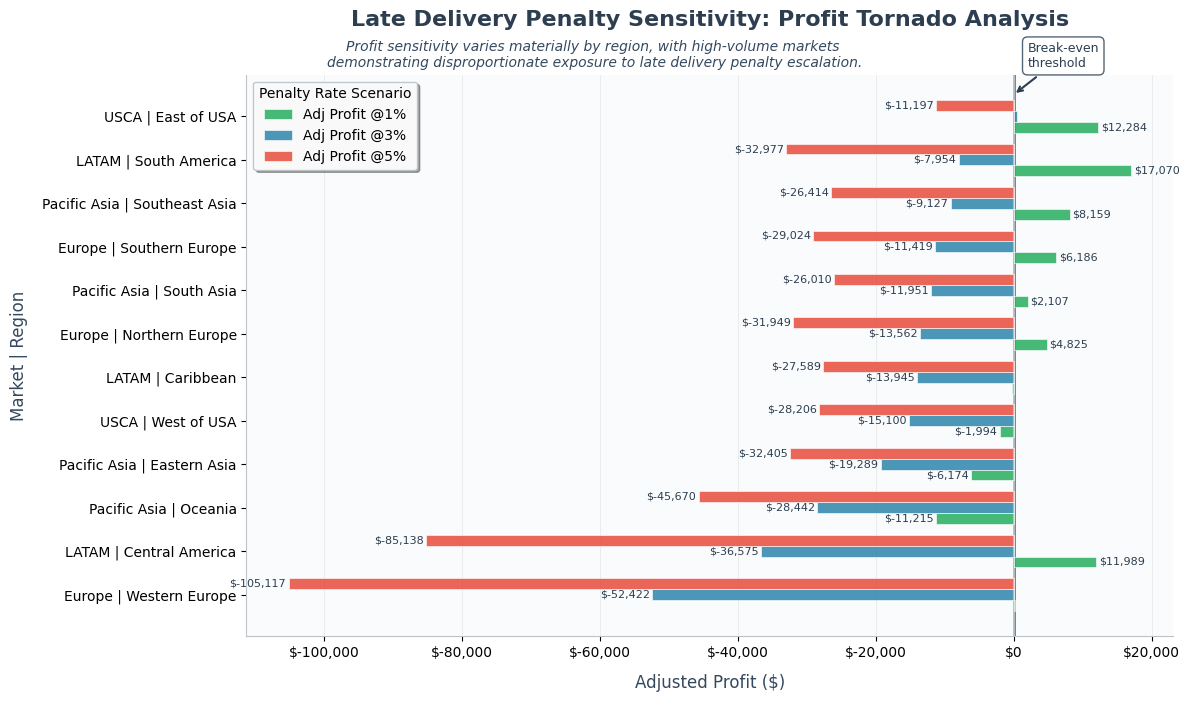

In [ ]:
# ----- Tornado plot: profit sensitivity to late delivery penalty rate by region -----

# Visualises the two questions from the Sensitivity Analysis section:
#   1. How much does adjusted profit swing between optimistic (1%) and stress (5%)?
#   2. Which regions cross the zero-profit line under worsening assumptions?
# Regions are ranked by sensitivity (swing magnitude) and ordered by base-case (3%)
# adjusted profit so the zero line becomes the decision threshold.

df_sens = sensitivity_df.copy()

# Validate required columns
penalty_levels = [0.01, 0.03, 0.05]

required_cols = {"market", "order_region", "penalty_rate", "adj_profit"}
missing = required_cols - set(df_sens.columns)
if missing:
    raise ValueError(f"Missing required columns in sensitivity_results: {missing}")

tornado_df = df_sens[df_sens["penalty_rate"].isin(penalty_levels)].copy()

# Build region label for y-axis
tornado_df["region"] = tornado_df["market"].astype(str) + " | " + tornado_df["order_region"].astype(str)

# Pivot: regions as rows, penalty rates as columns
tornado_pivot = tornado_df.pivot_table(
    index = "region",
    columns = "penalty_rate",
    values = "adj_profit",
    aggfunc = "sum"
).sort_index()

# Ensure all three penalty levels exist in columns
for p in penalty_levels:
    if p not in tornado_pivot.columns:
        tornado_pivot[p] = 0.0

tornado_pivot = tornado_pivot[penalty_levels]
tornado_pivot.columns = ["Adj Profit @1%", "Adj Profit @3%", "Adj Profit @5%"]

# Sensitivity metric: profit swing from optimistic to stress scenario
tornado_pivot["swing_1_to_5"] = tornado_pivot["Adj Profit @1%"] - tornado_pivot["Adj Profit @5%"]

# Select top 12 most sensitive regions, ordered by base-case profitability
TOP_N = 12
tornado_plot = (
    tornado_pivot
    .assign(abs_swing = lambda x: x["swing_1_to_5"].abs())
    .sort_values("abs_swing", ascending = False)
    .head(TOP_N)
    .sort_values("Adj Profit @3%")  # base-case order highlights zero-line crossings
    .drop(columns = ["abs_swing", "swing_1_to_5"])
)

# Plot
plt.figure(figsize = (12, 8), facecolor = 'white')
fig = plt.gcf()
ax = plt.gca()

# Color palette for penalty rates
penalty_colors = {
    "Adj Profit @1%": '#27AE60',   # Green for optimistic scenario
    "Adj Profit @3%": '#2E86AB',   # Teal blue for base case
    "Adj Profit @5%": '#E74C3C'    # Red for stress scenario
}

y_pos = range(len(tornado_plot))

# Create grouped horizontal bars
bar_height = 0.25
for i, (col, color) in enumerate(penalty_colors.items()):
    offset = (i - 1) * bar_height  # Center the group
    bars = plt.barh(
        [y + offset for y in y_pos], 
        tornado_plot[col],
        height = bar_height,
        color = color,
        alpha = 0.85,
        label = col,
        edgecolor = 'white',
        linewidth = 0.5,
        zorder = 3
    )
    
    # Add value labels on bars
    for bar in bars:
        width = bar.get_width()
        if abs(width) > 0.01 * max(abs(tornado_plot.values.flatten())):
            plt.text(
                width + (0.02 * max(tornado_plot.values.flatten()) if width > 0 else -0.02 * max(tornado_plot.values.flatten())),
                bar.get_y() + bar.get_height()/2,
                f'${width:,.0f}',
                va = 'center',
                ha = 'left' if width > 0 else 'right',
                fontsize = 8,
                color = '#2C3E50',
                fontweight = 'normal'
            )

plt.yticks(y_pos, tornado_plot.index, fontsize = 10)
plt.axvline(0, linewidth = 2, color = '#2C3E50', linestyle = '-', alpha = 0.7, zorder = 2)
plt.axvline(0, linewidth = 1.5, color = 'white', linestyle = '-', alpha = 0.5, zorder = 3)  # White line over for clarity

# Title and subtitle
plt.title("Late Delivery Penalty Sensitivity: Profit Tornado Analysis", 
          fontsize = 16, 
          fontweight = 'bold',
          pad = 35,
          color = '#2C3E50')
plt.figtext(0.5, 0.83, 
            "Profit sensitivity varies materially by region, with high-volume markets \ndemonstrating disproportionate exposure to late delivery penalty escalation.", 
            ha = "center", 
            fontsize = 10, 
            style = "italic", 
            color = '#34495E')

plt.xlabel("Adjusted Profit ($)", 
           fontsize = 12, 
           fontweight = 'normal', 
           labelpad = 10,
           color = '#34495E')
plt.ylabel("Market | Region", 
           fontsize = 12, 
           fontweight = 'normal', 
           labelpad = 10,
           color = '#34495E')

# Format x-axis
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

# Legend
plt.legend(
    loc = 'upper left',
    frameon = True,
    fancybox = True,
    shadow = True,
    fontsize = 10,
    framealpha = 0.95,
    edgecolor = '#BDC3C7',
    title = "Penalty Rate Scenario",
    title_fontsize = 10
)

# Plot grid - add vertical lines for reference
plt.grid(True, axis = 'x', alpha = 0.3, linestyle = '-', linewidth = 0.5, zorder = 0)

# Clean up spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#BDC3C7')
ax.spines['bottom'].set_color('#BDC3C7')

# Set background
ax.set_facecolor('#FAFBFC')

# Add annotation for zero-profit line
plt.annotate(
    'Break-even\nthreshold',
    xy = (0, len(tornado_plot) - 0.5),
    xytext = (10, 20),
    textcoords = 'offset points',
    fontsize = 9,
    color = '#2C3E50',
    fontweight = 'normal',
    bbox = dict(boxstyle = 'round,pad = 0.4', facecolor = 'white', edgecolor = '#2C3E50', alpha = 0.8),
    arrowprops = dict(arrowstyle = '->', color = '#2C3E50', lw = 1.5),
    ha = 'left'
)

plt.tight_layout(rect = [0, 0.03, 1, 0.92])

plt.show()

### Late Delivery Penalty Sensitivity Analysis

**(SCOR: Deliver → Measure)**

The tornado plot shows adjusted profit for the 12 most penalty-sensitive regions under three scenarios: 1% (optimistic), 3% (base case), and 5% (stress). Regions are ordered by base-case adjusted profit so the vertical line at zero becomes the decision threshold.

#### Findings

1. **The 3% base case is a tipping point for multiple regions.** South America, Southern Europe, and Southeast Asia are marginally profitable at 1% but turn negative at 3%. These regions do not require structural redesign, they require service reliability improvements sufficient to avoid the penalty escalation that the 3% rate represents. A reduction in late delivery rates from ~55% toward ~45% would move these regions back across the zero line without any change to the penalty rate assumption.

2. **Five regions are structurally fragile, loss-making even at 1%.** The Caribbean, West USA, Central Africa, West Asia, and Eastern Europe show negative adjusted profit under the most optimistic scenario. Service improvement alone will not restore profitability here; these regions require discount reduction or pricing intervention in addition to delivery reliability gains.

3. **Only two regions remain profitable at 5% stress.** Canada and East Africa retain positive adjusted margins under the worst-case assumption. These are the enterprise's service-risk-insulated profit zones. They warrant protection, not intervention.

#### Regional Sensitivity Archetypes
|Archetype |Regions |Behaviour |Primary Lever|
|----------|--------|----------|-------------|
|Margin-Resilient |Canada, East Africa |Profitable at all three rates |Protect; monitor|
|Tipping-Point |South America, Southern Europe, Southeast Asia, Oceania |Profitable at 1%, negative at 3% |Service reliability improvement|
|Structurally Fragile |Caribbean, West USA, Central Africa, West Asia, Eastern Europe |Negative at all three rates |Discount reduction + service improvement|

The sensitivity analysis confirms that the 3% base-case assumption is not conservative, it is the rate at which the enterprise's service fragility becomes visible. Under a 1% assumption, the portfolio appears largely viable. Under 3%, the margin compression documented throughout this notebook becomes explicit. The implication is that service reliability investment should be sized against the avoided cost of crossing from the 1% to the 3% scenario for tipping-point regions - approximately $50-80K in recovered penalty costs across the top five exposed regions.

## Strategic Recommendations: Margin Recovery Levers

The analysis identified discount leakage as the dominant profit destroyer (3.26M), late delivery penalties as a secondary but compounding cost (477K), and returns as a minor leakage channel (73K). The uniformity of discount rates (roughly 11-12%) and late rates (roughly 53-56%) across all regions and categories indicates these are enterprise policy conditions, not localised problems. The following three actions are ordered by expected margin recovery.

#### 1. Reduce discount leakage by 10% (enterprise-wide)

**Finding:** Discount rates are near-identical across markets and categories (11.0-12.5% of sales). This is a centralised pricing policy, not a market-specific tactic. Discount leakage alone consumes 94% of reported profit.

**Action:** Apply a uniform 1.1-percentage-point reduction to the enterprise discount rate (from ~11.2% to ~10.1% of sales). This is a policy adjustment, not a market-by-market renegotiation.

**Expected impact:** ~326K recovered - sufficient to move adjusted profit from -260K to approximately +66K.

**Implementation:** The reduction should be applied universally given the uniformity of current rates. If selective application is required, prioritise categories where discount intensity most exceeds margin capacity: Strength Training (12.46% discount rate, -13.28% adjusted margin), Men's Clothing (11.40%, -7.94%), and Hunting and Shooting (11.70%, -1.70%).

#### 2. Reduce late delivery rates by 20% in tipping-point regions

**Finding:** Five regions - South America, Southern Europe, Southeast Asia, Oceania, and Eastern Europe - are profitable under the 1% penalty scenario but turn loss-making at the 3% base case. Their combined late-penalty exposure is approximately $215K at the 3% rate.

**Action:** Target a late-rate reduction from ~55% to ~44% in these five regions through carrier mix adjustments, shipping mode optimisation for high-value orders, and fulfillment node rebalancing.

**Expected impact:** A 20% penalty reduction across these five regions recovers ~43K. Combined with the discount reduction above, adjusted profit reaches approximately +109K.

**Implementation priority:** South America and Southern Europe (largest absolute penalty exposure). Oceania and Southeast Asia (geographically distributed risk requiring carrier-level intervention). Eastern Europe (smallest exposure of the five; address last).

#### 3. Monitor returns; do not invest in return policy changes

**Finding:** Returns account for $73K of total leakage (2.1% of reported profit). Return rates are low (1.0-2.8%) and uniform across regions. No region or category shows return leakage sufficient to justify enterprise-level policy intervention.

**Action:** Track return rates in Canada (2.82%) and Southern Africa (2.63%) as early-warning indicators. Monitor apparel categories (Children's Clothing: 2.76%, Baby: 2.9%) for fit and sizing-related return patterns. Restocking fees, return thresholds, or policy changes should not be introduced at current leakage levels.

**Rationale:** The ROI on return policy changes is negative - the implementation cost would likely exceed the recoverable leakage. Resources should be directed to discount governance and service reliability, where the margin recovery potential is 6-7x larger.

#### Summary
|Lever |Current Leakage ($) |Target Reduction |Expected Recovery ($) |Priority|
|------|----------------------|-----------------|------------------------|--------|
|Discount governance |3.26M |10% |~326K |1|
|Late delivery (tipping-point regions) |~215K |20% |~43K |2|
|Return policy changes |73K | - |Not recommended |3|

Combined impact of levers 1 and 2: adjusted profit moves from -260K to approximately +109K. Neither action requires demand growth, capital investment, or structural reorganisation. Both are policy adjustments executable within current operations.

This financial diagnostic is designed to pair with the Demand Forecasting notebook. Together, they answer the two questions that determine supply chain profitability:

|Layer |Notebook |Question|
|------|---------|--------|
|Plan/Deliver |Demand Forecasting |Where will demand occur?|
|Measure/Return |Financial Impact |Will that demand be profitable?|

The recommendations above - discount governance, service reliability improvement in tipping-point regions, and return monitoring - are the highest-ROI actions to ensure that forecasted demand converts to retained profit. Neither revenue growth nor forecast accuracy alone will close the gap between reported profit (+3.48M) and adjusted profit (-260K). Only policy change will.